# AI Overview Tracker: Presence, Cited Domains and Your Share

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lazarinastoy/mlforseo-code/blob/main/ai-overview-tracker/ai_overview_tracker.ipynb)

By **Lazarina Stoy, [MLforSEO](https://www.mlforseo.com/)**. Free, MIT licence.

Your rank tracker tells you where you rank in the blue links. It usually doesn't tell you whether Google answered the query with an AI Overview first, or whose pages that answer cited. This notebook does, for any keyword list:

1. **Presence**: does an AI Overview appear for each keyword?
2. **Citations**: which URLs and domains does it cite, and in what order?
3. **You**: is your domain cited, at which position, and where do you rank organically?
4. **Share**: each domain's share of all citations across your keyword set, as a table and a chart.
5. **Gaps**: keywords where an AI Overview shows, competitors are cited and you aren't.
6. **Cited vs ranking**: who gets cited without ranking in the top 10, and who ranks without being cited.
7. **History**: each run is appended to a history file, so you can track it week by week.

It uses the DataForSEO SERP API v3 (Google Organic, Live Advanced or Standard), with the collection code from the [DataForSEO SERP Collection Starter Notebook](https://github.com/lazarinastoy/mlforseo-code/tree/main/dataforseo-serp-collection).

**What you need:** a DataForSEO API login and password ([app.dataforseo.com/api-access](https://app.dataforseo.com/api-access)). To try it first, leave `USE_SAMPLE = True`: it runs on three real US SERPs pulled on 24 October 2026, with `screamingfrog.co.uk` as the example "your domain" (it's cited in the AI Overview for "screaming frog download" without ranking in that SERP's organic top 10, which makes a useful example).

**What it costs (October 2026 list prices):** about $0.002 per keyword in Live mode plus up to $0.002 for loading asynchronous AI Overviews (refunded when there isn't one), so at most $0.40 per 100 keywords. Standard mode is about a third of that.

## 1. Setup

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path
warnings.filterwarnings("ignore", message=".*OpenSSL.*")  # harmless urllib3 notice on some Macs

REPO_RAW = "https://raw.githubusercontent.com/lazarinastoy/mlforseo-code/main/ai-overview-tracker"
FILES = ["dataforseo_serp.py", "aio_tracker.py", "sample_data/keywords.csv",
         "sample_data/what-is-entity-seo.json", "sample_data/best-running-shoes.json",
         "sample_data/screaming-frog-download.json"]

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pandas", "requests", "openpyxl", "matplotlib"], check=True)
for f in FILES:
    if not Path(f).exists():
        Path(f).parent.mkdir(parents=True, exist_ok=True)
        subprocess.run(["wget", "-q", "-O", f, f"{REPO_RAW}/{f}"], check=True)

import pandas as pd
import dataforseo_serp as dfs
import aio_tracker as aio
pd.set_option("display.max_colwidth", 80)
print("Ready.")

Ready.


## 2. Settings

* `MY_DOMAIN`: your site, without `https://` or `www.`. Subdomains count as you (`blog.example.com` matches `example.com`).
* `COMPETITORS`: optional. If you list domains, the gap report only keeps keywords where one of them is cited.
* `LOAD_ASYNC_AI_OVERVIEW` should stay `True`. Many AI Overviews load after the rest of the page; without this flag DataForSEO only returns the ones already in the page, and your presence rate would be too low.
* `MAX_SPEND_USD` is a hard stop on paid calls for the run.

In [2]:
USE_SAMPLE = True                 # False = call the real API with your credentials

MY_DOMAIN = "screamingfrog.co.uk"  # change to your domain
COMPETITORS = []                   # e.g. ["competitor-one.com", "competitor-two.co.uk"]

MODE = "live"                     # "live" (instant) or "standard" (queued, cheaper)
LOCATION_CODE = 2840              # 2840 = United States, 2826 = United Kingdom
LANGUAGE_CODE = "en"
DEVICE = "desktop"
LOAD_ASYNC_AI_OVERVIEW = True
MAX_SPEND_USD = 0.10
MAX_KEYWORDS = 200

KEYWORDS_CSV = "sample_data/keywords.csv"   # a CSV with a `keyword` column
KEYWORDS = []                               # or paste a list here

## 3. Keywords and the cost estimate

In [3]:
keywords = dfs.clean_keywords(KEYWORDS or pd.read_csv(KEYWORDS_CSV)["keyword"].tolist())
if len(keywords) > MAX_KEYWORDS:
    raise ValueError(f"{len(keywords)} keywords is over MAX_KEYWORDS ({MAX_KEYWORDS}).")
est = dfs.estimate_cost(len(keywords), mode=MODE, depth=10, load_async_ai_overview=LOAD_ASYNC_AI_OVERVIEW)
print(f"{len(keywords)} keywords. Worst-case cost: ${est['usd_total_max']:.3f} ({MODE} mode)")
if not USE_SAMPLE and est["usd_total_max"] > MAX_SPEND_USD:
    print(f"The estimate is above MAX_SPEND_USD (${MAX_SPEND_USD}); the run will stop at the cap.")
keywords

3 keywords. Worst-case cost: $0.012 (live mode)


['what is entity seo', 'best running shoes', 'screaming frog download']

## 4. Collect the SERPs

In Colab, add `DATAFORSEO_LOGIN` and `DATAFORSEO_PASSWORD` as secrets (key icon, left sidebar). Otherwise you'll get a hidden prompt. Nothing is saved to the notebook.

Depth stays at 10: AI Overviews sit at the top of the page, and the organic top 10 is enough for the cited-vs-ranking comparison.

In [4]:
if USE_SAMPLE:
    client = dfs.SampleClient("sample_data")
else:
    client = dfs.DataForSEOClient(*dfs.get_credentials(), max_spend_usd=MAX_SPEND_USD)

responses = client.collect(keywords, mode=MODE, location_code=LOCATION_CODE, language_code=LANGUAGE_CODE,
                           device=DEVICE, depth=10, load_async_ai_overview=LOAD_ASYNC_AI_OVERVIEW)
tables = dfs.flatten(responses)
print(f"{len(responses)} SERPs. Spent: ${client.spent:.4f}" + ("  (sample replay, free)" if USE_SAMPLE else ""))

3 SERPs. Spent: $0.0000  (sample replay, free)


## 5. AI Overview presence, and whether you're cited

In DataForSEO's advanced SERP response an AI Overview is an item with `type: "ai_overview"`. Its answer is split into `ai_overview_element` paragraphs, and each paragraph carries a `references` list (`domain`, `url`, `title`, `source`). The item also has its own `references`: the source cards beside the answer. The tracker reads both and counts each cited URL once per keyword, in order of first appearance, so `your_first_citation_position` 1 means you're the first source the answer leans on.

In [5]:
presence = aio.aio_presence(tables, MY_DOMAIN)
n_aio = int(presence["has_ai_overview"].sum())
print(f"AI Overview on {n_aio} of {len(presence)} keywords ({n_aio / max(len(presence), 1):.0%}).")
print(f"{MY_DOMAIN} cited in {int(presence['you_cited'].sum())} of them.")
presence

AI Overview on 3 of 3 keywords (100%).
screamingfrog.co.uk cited in 1 of them.


,keyword,has_ai_overview,cited_urls,cited_domains,you_cited,your_first_citation_position,your_cited_urls,your_organic_rank,top_cited_domains
0,what is entity seo,True,10,8,False,NaN,,None,"neilpatel.com, demandspring.com, inlinks.com"
1,best running shoes,True,3,3,False,NaN,,None,"runrepeat.com, fleetfeet.com, rtings.com"
2,screaming frog download,True,6,2,True,1.0,https://www.screamingfrog.co.uk/seo-spider/ | https://www.screamingfrog.co.u...,None,"screamingfrog.co.uk, youtube.com"


## 6. Share of citations by domain

`share_of_citations` is the domain's cited URLs divided by all cited URLs across the keyword set. `keyword_coverage` is the share of AI Overviews that cite the domain at least once. Coverage is usually the more useful number: one domain cited four times in a single answer looks big on share, but it's still one answer.

In [6]:
share = aio.citation_share(tables["ai_overview_citations"], MY_DOMAIN, n_aio)
share.head(15)

,domain,citations,share_of_citations,keywords_cited_in,keyword_coverage,is_you
0,youtube.com,4,0.211,2,0.667,False
1,screamingfrog.co.uk,4,0.211,1,0.333,True
2,schemaapp.com,2,0.105,1,0.333,False
3,ahrefs.com,1,0.053,1,0.333,False
4,demandspring.com,1,0.053,1,0.333,False
5,fleetfeet.com,1,0.053,1,0.333,False
6,inlinks.com,1,0.053,1,0.333,False
7,neilpatel.com,1,0.053,1,0.333,False
8,rtings.com,1,0.053,1,0.333,False
9,runrepeat.com,1,0.053,1,0.333,False


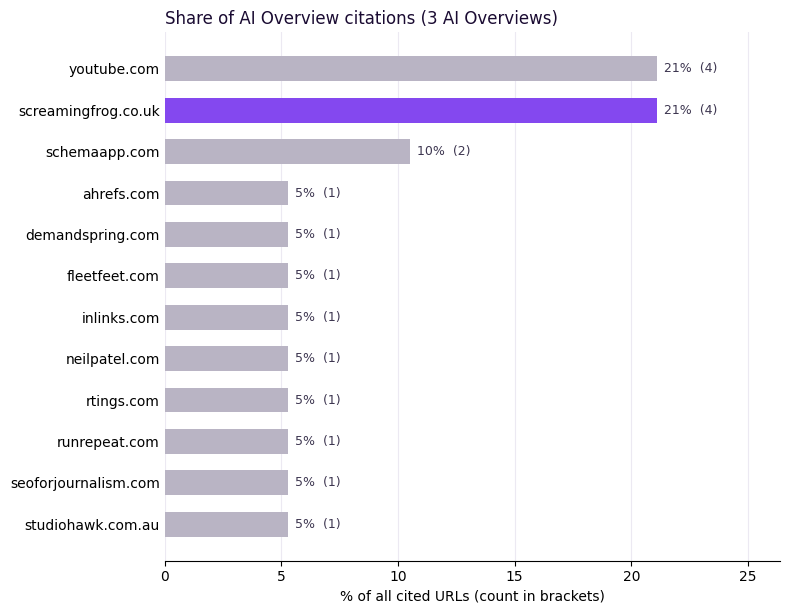

In [7]:
Path("output").mkdir(exist_ok=True)
fig = aio.plot_share(share, top_n=12, title=f"Share of AI Overview citations ({n_aio} AI Overviews)",
                     path="output/citation_share.png")

## 7. Gaps: AI Overviews that cite others and not you

These are the first keywords to look at. Open the SERP, read the answer and the cited pages, and ask what those pages say (or how clearly they say it) that yours doesn't. Your organic rank is alongside, because a page that ranks well and still isn't cited is a different problem from a page that isn't ranking at all.

In [8]:
gaps = aio.citation_gaps(presence, tables["ai_overview_citations"], COMPETITORS or None)
gaps

,keyword,cited_instead,your_organic_rank
0,what is entity seo,"neilpatel.com, demandspring.com, inlinks.com, schemaapp.com, ahrefs.com, you...",None
1,best running shoes,"runrepeat.com, fleetfeet.com, rtings.com",None


## 8. Cited vs ranking

For each keyword: domains that are both cited and in the organic top 10, domains cited without ranking there, and domains ranking without being cited. A low `overlap_pct` means the AI Overview is drawing on a different set of pages than the blue links, which is exactly what a rank tracker can't show you.

In [9]:
aio.cited_vs_ranking(tables, top_n=10)

,keyword,cited_and_ranking,cited_not_ranking,ranking_not_cited,overlap_pct
0,what is entity seo,"ahrefs.com, inlinks.com, neilpatel.com, schemaapp.com, seoforjournalism.com,...","demandspring.com, studiohawk.com.au","clearscope.io, found.co.uk, searchengineland.com",75.0
1,best running shoes,,"fleetfeet.com, rtings.com, runrepeat.com","brooksrunning.com, reddit.com, roadrunnersports.com, runnersworld.com, theru...",0.0
2,screaming frog download,,"screamingfrog.co.uk, youtube.com","appsumo.com, community.chocolatey.org, download.cnet.com, manageengine.com, ...",0.0


## 9. Export and keep a history

Writes the tables to `output/` as CSVs plus one workbook (`ai_overview_tracker.xlsx`) that imports into Google Sheets with *File → Import → Upload*. Each run is also appended to `output/aio_history.csv` (one row per keyword per day), so if you run this weekly you'll build a trend line of presence and citations.

In [10]:
export_tables = {
    "aio_presence": presence,
    "citation_share": share,
    "citation_gaps": gaps,
    "cited_vs_ranking": aio.cited_vs_ranking(tables, top_n=10),
    "aio_citations": tables["ai_overview_citations"],
    "organic": tables["organic"],
}
for p in dfs.export(export_tables, "output", xlsx_name="ai_overview_tracker.xlsx"):
    print(p)
run_date = tables["serp_features"]["date"].max()  # the date the SERPs were collected
history = aio.append_history(presence, "output/aio_history.csv", run_date=run_date)
print(f"history: {len(history)} rows")

output/aio_presence.csv
output/citation_share.csv
output/citation_gaps.csv
output/cited_vs_ranking.csv
output/aio_citations.csv
output/organic.csv
output/ai_overview_tracker.xlsx
history: 3 rows


## Limits and honest caveats

* **AI Overviews are volatile.** The same query can show a different answer, different sources, or no AI Overview at all an hour later. One run is a snapshot. Run it on a schedule and read the trend, not a single day.
* **One location, language and device per run.** Results in the UK, on mobile or for a logged-in user can differ.
* **Presence depends on `load_async_ai_overview`.** With it off, you'll undercount AI Overviews.
* **Citations are what Google displays as sources.** They don't tell you how much of the answer came from each page, or whether anyone clicked.
* **AI Mode is a separate surface** (DataForSEO has a separate `ai_mode` endpoint). This notebook tracks AI Overviews in the regular results only.
* Prices are DataForSEO's and change; the run's real cost is in `client.cost_log`.

## What to do next

* Read [Your rank tracker is lying to you about AI search](https://www.mlforseo.com/machine-learning-implementation-guides/ai-search-optimisation/rank-tracker-ai-search-measurement/) for why this measurement gap matters and what else to track.
* If you're new to the API, start with the [DataForSEO SERP Collection Starter Notebook](https://github.com/lazarinastoy/mlforseo-code/tree/main/dataforseo-serp-collection). For AI Mode, historical SERPs and LLM answers, see [`serp-analysis-machine-learning/`](https://github.com/lazarinastoy/mlforseo-code/tree/main/serp-analysis-machine-learning).
* Turning these gaps into content and entity work is what the [AI Search Optimisation & Agentic SEO course](https://www.mlforseo.com/courses/ai-search-optimisation-agentic-seo/) covers.